# 01 — Exploratory Data Analysis

Exploring the IEEE-CIS Fraud Detection dataset: class imbalance, fraud dynamics over time,
missing values and key features. Raw data rows are not shown in the committed outputs
(competition rules forbid redistribution).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from fraud.data import load_train

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.12.15
pandas: 3.0.6
numpy: 2.5.4


## 1. Raw data overview

In [2]:
RAW_DIR = Path("../data/raw")
start = time.perf_counter()
transactions = pd.read_csv(RAW_DIR / "train_transaction.csv")
identity = pd.read_csv(RAW_DIR / "train_identity.csv")
elapsed = time.perf_counter() - start

print(f"Loaded in {elapsed:.1f} s")
print(f"transactions: {transactions.shape[0]:,} rows x {transactions.shape[1]} columns")
print(f"identity:     {identity.shape[0]:,} rows x {identity.shape[1]} columns")

Loaded in 22.8 s
transactions: 590,540 rows x 394 columns
identity:     144,233 rows x 41 columns


In [3]:
def memory_mb(df):
    """Return the DataFrame memory footprint in megabytes."""
    return df.memory_usage(deep=True).sum() / 1024 ** 2

print(f"transactions: {memory_mb(transactions):,.0f} MB")
print(f"identity:     {memory_mb(identity):,.0f} MB")

transactions: 1,792 MB
identity:     57 MB


In [4]:
transactions.dtypes.value_counts()

float64    376
str         14
int64        4
Name: count, dtype: int64

In [5]:
has_identity = transactions["TransactionID"].isin(identity["TransactionID"])
print(f"Transactions with identity info: {has_identity.mean():.1%}")

Transactions with identity info: 24.4%


## 2. Merging tables and reducing memory

In [6]:
train = transactions.merge(identity, on="TransactionID", how="left", validate="one_to_one")
del transactions, identity

print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"memory: {memory_mb(train):,.0f} MB")

train: 590,540 rows x 434 columns
memory: 1,984 MB


In [7]:
def reduce_memory(df, keep=("TransactionAmt",)):
    """Downcast numeric columns and convert text columns to category, in place."""
    for col in df.columns:
        if col in keep:
            continue
        if pd.api.types.is_integer_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast="integer")
        elif pd.api.types.is_float_dtype(df[col]):
            df[col] = df[col].astype("float32")
        elif pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].astype("category")
    return df

In [8]:
before = memory_mb(train)
train = reduce_memory(train)
after = memory_mb(train)

print(f"memory: {before:,.0f} MB -> {after:,.0f} MB ({before / after:.1f}x smaller)")

memory: 1,984 MB -> 926 MB (2.1x smaller)


In [9]:
train.dtypes.value_counts()

float32     398
category     12
category      4
int32         2
int8          1
float64       1
category      1
int16         1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
Name: count, dtype: int64

## 3. Saving the merged table
Parquet keeps dtypes (including categories)

In [10]:
INTERIM_DIR = Path("../data/interim")
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

train.to_parquet(INTERIM_DIR / "train.parquet", index=False)

size_mb = (INTERIM_DIR / "train.parquet").stat().st_size / 1024**2
print(f"saved: {size_mb:,.0f} MB")

saved: 80 MB


## 4. Target: class imbalance
This section examines the distribution of fraudulent and legitimate transactions to identify class imbalance.

In [11]:
train = load_train()
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")

In [14]:
counts = train['isFraud'].value_counts()
fraud_rate = train['isFraud'].mean()

print(f'not fraud: {counts[0]}')
print(f'fraud: {counts[1]}')
print(f'fraud rate: {fraud_rate:.2%}')

not fraud: 569877
fraud: 20663
fraud rate: 3.50%


## 5. Does Fraud Change Over Time?

This section examines how fraud frequency and fraud rates change over time.

In [15]:
SECONDS_PER_DAY = 24 * 60 * 60
train['day'] = train['TransactionDT'] // SECONDS_PER_DAY
print(f'days covered {train["day"].min()} .. {train['day'].max()}')

days covered 1 .. 182


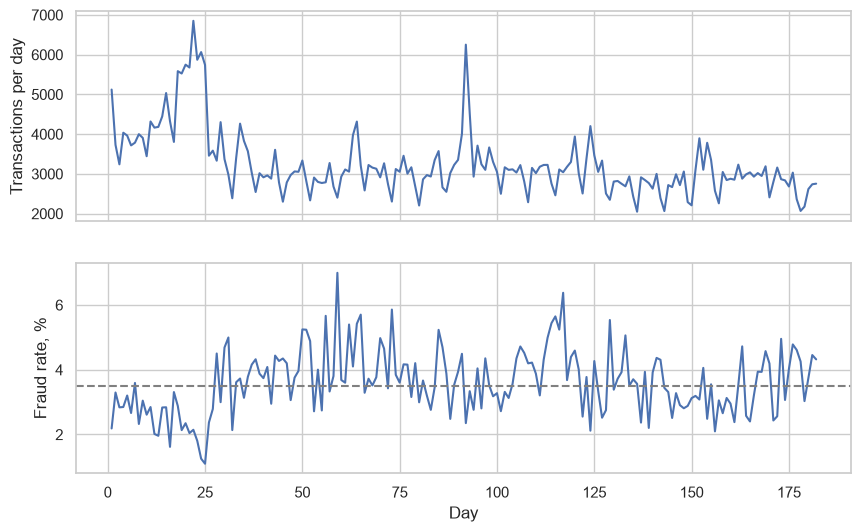

In [16]:
daily = train.groupby("day")["isFraud"].agg(transactions="size", fraud_rate="mean")
daily["fraud_rate"] = daily["fraud_rate"] * 100

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(daily.index, daily["transactions"])
axes[0].set_ylabel("Transactions per day")

axes[1].plot(daily.index, daily["fraud_rate"])
axes[1].axhline(fraud_rate * 100, color="gray", linestyle="--")
axes[1].set_ylabel("Fraud rate, %")
axes[1].set_xlabel("Day")

plt.show()

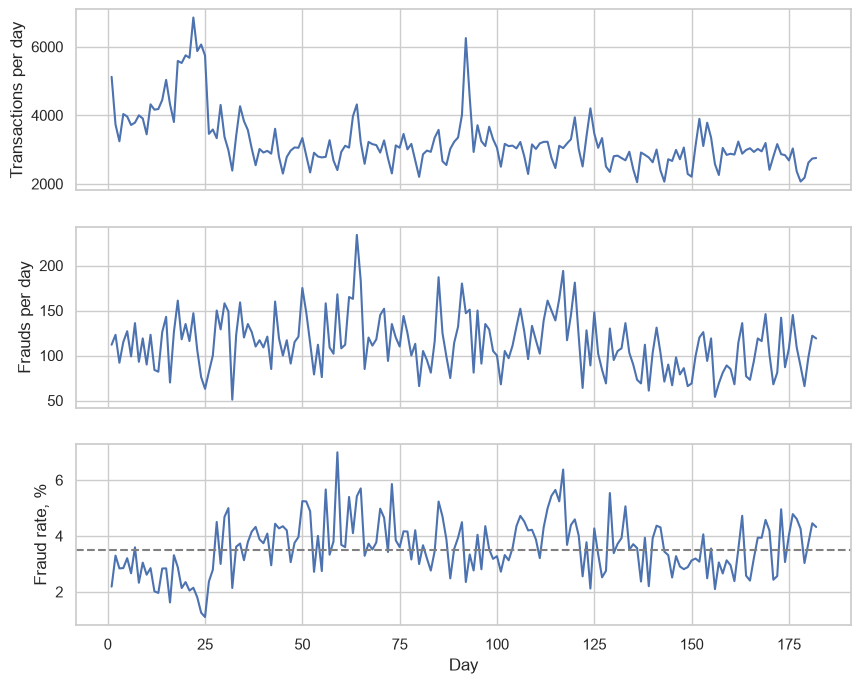

In [18]:
daily = train.groupby("day")["isFraud"].agg(transactions="size", frauds="sum", fraud_rate="mean")
daily["fraud_rate"] = daily["fraud_rate"] * 100

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(daily.index, daily["transactions"])
axes[0].set_ylabel("Transactions per day")

axes[1].plot(daily.index, daily["frauds"])
axes[1].set_ylabel("Frauds per day")

axes[2].plot(daily.index, daily["fraud_rate"])
axes[2].axhline(fraud_rate * 100, color="gray", linestyle="--")
axes[2].set_ylabel("Fraud rate, %")
axes[2].set_xlabel("Day")

plt.show()

The dataset starts in a high-volume period (4,600 transactions/day for the first 24 days, likely the December
holiday season), then settles at 3,000/day. The fraud *rate* jumps from 2.5% to 4% right after that drop,
but the number of frauds per day stays roughly flat (115–125): the rate changes mostly because the denominator
(legitimate volume) shrinks, not because fraud itself grows. After day 120 the rate returns to 3.5%.

Conclusion: the data is non-stationary and seasonal, so the model must be validated on the *last* months
(time-based split), not on a random sample. Time-of-day and day features are likely to help.